In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures



In [2]:
df = pd.read_csv('Icecream Sales wr Rain and Temperature.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Temperature (F)                 20 non-null     float64
 1   Ice-cream Price ($)             20 non-null     float64
 2   Number of Tourists (thousands)  20 non-null     float64
 3   Ice Cream Sales ($,thousands)   20 non-null     int64  
 4   Did it rain on that day?        20 non-null     object 
dtypes: float64(3), int64(1), object(1)
memory usage: 932.0+ bytes


In [4]:
df.corr(numeric_only=True)

,Temperature (F),Ice-cream Price ($),Number of Tourists (thousands),"Ice Cream Sales ($,thousands)"
Temperature (F),1.000000,0.039864,0.779084,0.862798
Ice-cream Price ($),0.039864,1.000000,0.045092,0.094629
Number of Tourists (thousands),0.779084,0.045092,1.000000,0.933405
"Ice Cream Sales ($,thousands)",0.862798,0.094629,0.933405,1.000000


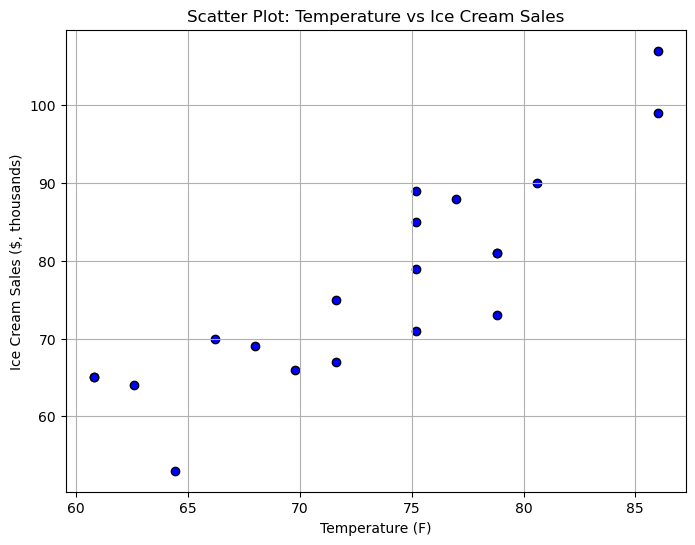

In [5]:
plt.figure(figsize=(8, 6))
plt.scatter(df['Temperature (F)'], df['Ice Cream Sales ($,thousands)'], color='blue', edgecolor='k')
plt.xlabel('Temperature (F)')
plt.ylabel('Ice Cream Sales ($, thousands)')
plt.title('Scatter Plot: Temperature vs Ice Cream Sales')
plt.grid(True)
plt.show()

In [6]:
df['Did it rain on that day?'] = df['Did it rain on that day?'].map({'Yes': 1, 'No': 0})

In [7]:
x = df.drop(columns='Ice Cream Sales ($,thousands)') # Features (2D) 
y = df ['Temperature (F)'] # Target (1D)

In [8]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.8, random_state=42)

In [9]:
model = LinearRegression()
model.fit(xtrain, ytrain)

LinearRegression()

# Model evaluation


In [10]:
#Train Data
ytrain_pred = model.predict(xtrain)
train_score = r2_score(ytrain,ytrain_pred)
print(f'Train Score {train_score}')

#Test Data
ytest_pred = model.predict(xtest)
test_score = r2_score(ytest,ytest_pred)
print(f'Test Score {test_score}')

Train Score 1.0
Test Score 1.0


In [11]:
poly = PolynomialFeatures(degree=2)

In [12]:
updated_xtrain=poly.fit_transform(xtrain)
updated_xtest = poly.transform(xtest)

In [13]:
model_poly = LinearRegression()

model_poly.fit(updated_xtrain, ytrain)

LinearRegression()

# Model Evaluation

In [14]:
#Train Data
ytrain_pred = model_poly.predict(updated_xtrain)
train_score = r2_score(ytrain,ytrain_pred)
print(f'Train Score {train_score}')

#Test Data
ytest_pred = model_poly.predict(updated_xtest)
test_score = r2_score(ytest,ytest_pred) 
print(f'Test Score {test_score}')

Train Score 1.0
Test Score 0.9890511402891263
